# Thesis Ch. 4 §4.6: node sets and the reference-mean similarity figure

Recomputes, from the joint graph and the frozen node sets used by run 11, the numbers that §4.6 of
the thesis reports, and draws the figure comparing each evaluation paper's cosine similarity to the
mean embedding of its own references with its similarity to the reference means of the other
evaluation papers.

- Splits: `data/processed/joint/splits.json` (ogbn-arxiv's year split). Node sets:
  `data/frozen/eval_nodes_capped.json` (945 eval papers) and `data/frozen/training_sets_run9.json`
  (90,461 train / 806 validation), the sets run 11 uses.
- Recorded references = out-edges in `data/processed/joint/edges.csv`, self-loops removed (as the
  model's graph).
- Embeddings: raw `voyage-4-large` vectors (`node_embeddings.npy`), which run 11 uses
  (`--features raw`). Reference mean = plain mean of the reference embeddings; cosine is invariant to
  its length.

CPU only, under a minute. Output: `diagrams/figures/data/reference_mean_cosine.{pdf,png}`.

In [1]:
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../../diagrams")
import thesis_style as ts
ts.apply()

D = "../../data/"
nodes = pd.read_csv(D + "processed/joint/nodes.csv", usecols=["node_id", "year", "core"]).set_index("node_id")
edges = pd.read_csv(D + "processed/joint/edges.csv")
edges = edges[edges.src_node_id != edges.dst_node_id].drop_duplicates()
splits = json.load(open(D + "processed/joint/splits.json"))
run9 = json.load(open(D + "frozen/training_sets_run9.json"))
sets = {"eval": json.load(open(D + "frozen/eval_nodes_capped.json")), "valid": run9["valid"], "train": run9["train"]}
refs = edges.groupby("src_node_id").dst_node_id.apply(np.array)
X = np.load(D + "processed/joint/node_embeddings.npy", mmap_mode="r")

## Numbers for the thesis (§4.6)

In [2]:
for k, v in splits.items():
    y = nodes.loc[v, "year"]
    print(f"split {k}: {len(v):,} ogbn-arxiv papers, years {int(y.min())}-{int(y.max())}")
print()
for name, s in sets.items():
    deg = pd.Series([len(refs.get(n, [])) for n in s])
    yrs = nodes.loc[s, "year"].astype(int).value_counts().sort_index().to_dict()
    per = deg.value_counts()
    print(f"{name}: {len(s):,} papers, years {yrs}, all ogbn-arxiv: {nodes.loc[s, 'core'].all()}")
    print(f"   recorded references: min {deg.min()}, max {deg.max()}, mean {deg.mean():.1f}, median {deg.median():.0f}; "
          f"with >= 1: {(deg > 0).sum():,}; max papers per reference count {per.max()}")
a, b, c = map(set, sets.values())
print("\noverlaps eval/valid/train:", len(a & b), len(a & c), len(b & c))
print("train sets within the train split:", c <= set(splits["train"]), "| valid within 2018 split:", b <= set(splits["valid"]),
      "| eval within test split:", a <= set(splits["test"]))

split train: 90,941 ogbn-arxiv papers, years 1971-2017
split valid: 29,799 ogbn-arxiv papers, years 2018-2018
split test: 48,603 ogbn-arxiv papers, years 2019-2020

eval: 945 papers, years {2019: 750, 2020: 195}, all ogbn-arxiv: True
   recorded references: min 5, max 100, mean 51.8, median 52; with >= 1: 945; max papers per reference count 10
valid: 806 papers, years {2018: 806}, all ogbn-arxiv: True
   recorded references: min 5, max 100, mean 45.4, median 45; with >= 1: 806; max papers per reference count 10
train: 90,461 papers, years {1971: 1, 1986: 1, 1987: 1, 1988: 1, 1990: 3, 1991: 3, 1992: 1, 1993: 8, 1994: 19, 1995: 25, 1996: 31, 1997: 33, 1998: 121, 1999: 163, 2000: 260, 2001: 245, 2002: 350, 2003: 379, 2004: 405, 2005: 619, 2006: 949, 2007: 1287, 2008: 1915, 2009: 2480, 2010: 3532, 2011: 4390, 2012: 6393, 2013: 8091, 2014: 9105, 2015: 11988, 2016: 16276, 2017: 21386}, all ogbn-arxiv: True
   recorded references: min 0, max 518, mean 7.9, median 5; with >= 1: 83,259; max pap

## Figure: similarity of a paper to its own reference mean vs other papers' reference means

For each of the 945 evaluation papers: cosine between its own embedding and the mean embedding of its
own recorded references, and, as the baseline, cosines to the reference means of all 944 other
evaluation papers (892,080 values). Density histograms.

**Suggested caption:** Cosine similarity between the embedding of each of the 945 evaluation papers and
the mean embedding of its own recorded references, compared with its similarity to the reference means
of the other 944 evaluation papers.

In [3]:
def ref_means(s):
    M = np.stack([np.asarray(X[np.sort(refs[n])], dtype=np.float64).mean(0) for n in s])
    return M / np.linalg.norm(M, axis=1, keepdims=True)

stats = {}
for name in ["eval", "valid"]:
    s = sets[name]
    P = np.asarray(X[s], dtype=np.float64)
    S = P @ ref_means(s).T
    own = np.diag(S)
    other = S[~np.eye(len(s), dtype=bool)]
    better = (own[:, None] > np.where(np.eye(len(s), dtype=bool), -np.inf, S)).all(1)
    stats[name] = (own, other)
    print(f"{name}: own reference mean: mean {own.mean():.3f}, median {np.median(own):.3f}, 5-95% {np.percentile(own, 5):.3f}-{np.percentile(own, 95):.3f}")
    print(f"   other papers' reference means: mean {other.mean():.3f}, median {np.median(other):.3f}, 5-95% {np.percentile(other, 5):.3f}-{np.percentile(other, 95):.3f}")
    print(f"   papers whose own reference mean is more similar than every other paper's: {better.mean():.1%}")
    print(f"   own cosine above the 95th percentile of the baseline: {(own > np.percentile(other, 95)).mean():.1%}")

eval: own reference mean: mean 0.823, median 0.832, 5-95% 0.737-0.890
   other papers' reference means: mean 0.496, median 0.496, 5-95% 0.339-0.654
   papers whose own reference mean is more similar than every other paper's: 80.1%
   own cosine above the 95th percentile of the baseline: 98.9%


valid: own reference mean: mean 0.816, median 0.823, 5-95% 0.713-0.888
   other papers' reference means: mean 0.488, median 0.489, 5-95% 0.320-0.657
   papers whose own reference mean is more similar than every other paper's: 80.9%
   own cosine above the 95th percentile of the baseline: 98.6%


../../diagrams/figures/data/reference_mean_cosine.pdf


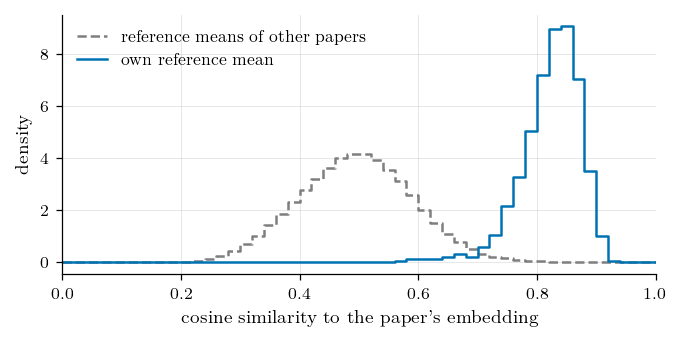

In [4]:
own, other = stats["eval"]
bins = np.linspace(0, 1, 51)
fig, ax = plt.subplots(figsize=(ts.FIGWIDTH, 55 * ts.MM), layout="constrained")
def step(x, **kw):
    h = np.histogram(x, bins=bins, density=True)[0]
    ax.step(bins, np.append(h, h[-1]), where="post", **kw)

step(other, color=ts.COLORS["grey"], linestyle="--", label="reference means of other papers")
step(own, color=ts.COLORS["blue"], label="own reference mean")
ax.set_xlim(0, 1)
ax.set_xlabel("cosine similarity to the paper's embedding")
ax.set_ylabel("density")
ax.legend(loc="upper left")
out = ts.save(fig, "reference_mean_cosine", outdir="../../diagrams/figures/data")
print(out)